# 02 ? Loan Default Classification

**MLE Group 1 ? Prosit 2**

**Classification owner:** Germain

This notebook consolidates saved results from
Checkpoints 7.0?7.3.

- Shared feature pipeline: Joseph
- Business cost assumptions: Liza
- Classification and evaluation: Germain

Model training is not repeated here.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()

if not (ROOT / "src/features.py").exists():
    ROOT = ROOT.parent

EXP = ROOT / "data/experiments"

THRESH = EXP / "step7_thresholds_20261026_221414"
CAL = EXP / "step7_calibration_20261026_215503"
BOOT = EXP / "step7_bootstrap_20261026_220225"
AUDIT = EXP / "step7_final_audit_20261026"

assert (THRESH / "threshold_comparison.csv").exists()


## 1. Experimental Provenance

The results in this notebook come from
previously completed classification experiments.

The final threshold analysis uses 54,463
evaluated loans.

This is different from the 68,464 processed
training records and requires reconciliation.

No Ghana-specific labelled evaluation has
been established by these simulations.


In [2]:
for folder in [THRESH, CAL, BOOT, AUDIT]:
    print(folder.relative_to(ROOT))

    for p in sorted(folder.glob("*.csv")):
        print(
            "  ",
            p.name,
            p.stat().st_size,
            "bytes"
        )


data\experiments\step7_thresholds_20261026_221414
   threshold_comparison.csv 2917 bytes
data\experiments\step7_calibration_20261026_215503
   fold_metrics.csv 12835 bytes
   oof_predictions.csv 87736938 bytes
   summary.csv 2162 bytes
data\experiments\step7_bootstrap_20261026_220225
   bootstrap_differences.csv 6457 bytes
   summary.csv 150 bytes
data\experiments\step7_final_audit_20261026
   calibration_diagnostic.csv 2067 bytes
   cost_sensitivity_verified.csv 2593 bytes


## 2. Classification Evaluation

Our experiments investigated predictive
discrimination, class imbalance, calibration,
validation strategy and model uncertainty.

PR-AUC is particularly relevant when loan
defaults are uncommon.

However, PR-AUC alone is not sufficient for
selecting a production lending model.


In [3]:
fold_metrics = pd.read_csv(
    CAL / "fold_metrics.csv"
)

display(fold_metrics)


,fold,model,calibration,n_fit,n_cal,n_valid,pr_auc,roc_auc,lift,brier,log_loss,predicted_risk,observed_risk
0,1,LR standard,none,2670,2385,13850,0.087746,0.779913,6.944434,0.012226,0.072264,0.003236,0.012635
1,1,LR standard,platt,2670,2385,13850,0.087746,0.779913,6.944434,0.012386,0.068790,0.005752,0.012635
2,1,LR standard,isotonic,2670,2385,13850,0.041354,0.744788,3.272899,0.012392,0.162058,0.003233,0.012635
3,1,LR balanced,none,2670,2385,13850,0.077952,0.772810,6.169377,0.014582,0.068454,0.024653,0.012635
4,1,LR balanced,platt,2670,2385,13850,0.077943,0.772804,6.168617,0.012441,0.067922,0.006216,0.012635
...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,4,RF balanced,platt,35333,13648,13587,0.131635,0.817118,3.355592,0.035875,0.143837,0.025644,0.039229
68,4,RF balanced,isotonic,35333,13648,13587,0.113246,0.808815,2.886812,0.036060,0.147755,0.023928,0.039229
69,4,LightGBM,none,35333,13648,13587,0.147067,0.815871,3.748975,0.037925,0.152412,0.040498,0.039229
70,4,LightGBM,platt,35333,13648,13587,0.147067,0.815871,3.748975,0.035972,0.145656,0.022633,0.039229


## 3. Probability Calibration

Platt calibration was evaluated alongside
alternative classification configurations.

Calibration matters because financial
decisions depend on predicted probabilities.

The diagnostics below are descriptive pooled
OOF summaries, not a replacement for
chronological fold-level verification.


In [4]:
calibration = pd.read_csv(
    AUDIT / "calibration_diagnostic.csv"
)

display(
    calibration.sort_values(
        ["model", "calibration"]
    )
)


,model,calibration,n_predictions,observed_default_rate,mean_predicted_risk,brier,ece_10_equal_width_bins
0,LR balanced,isotonic,54463,0.018141,0.010860,0.017129,0.007498
1,LR balanced,none,54463,0.018141,0.176070,0.080254,0.157929
2,LR balanced,platt,54463,0.018141,0.013806,0.017540,0.008962
3,LR regularized,isotonic,54463,0.018141,0.013642,0.017020,0.006020
4,LR regularized,none,54463,0.018141,0.014113,0.017411,0.008562
5,LR regularized,platt,54463,0.018141,0.016343,0.017569,0.008000
6,LR standard,isotonic,54463,0.018141,0.011964,0.017039,0.006929
7,LR standard,none,54463,0.018141,0.013029,0.017492,0.010306
8,LR standard,platt,54463,0.018141,0.014429,0.017143,0.007172
9,LightGBM,isotonic,54463,0.018141,0.012737,0.017074,0.005628


## 4. Bootstrap Confidence Intervals

Customer-cluster bootstrap analysis was used
to assess uncertainty in model comparisons.

Previously reported:

- LR minus RF PR-AUC: +0.03035
- 95% interval: [+0.0150, +0.0482]
- Valid bootstrap replicates: 300

These results support higher PR-AUC for LR
under the evaluated validation procedure.


In [5]:
bootstrap = pd.read_csv(
    BOOT / "bootstrap_differences.csv"
)

display(
    bootstrap.describe(include="all")
)


,bootstrap_difference
count,300.000000
mean,0.030827
std,0.008544
min,0.008064
25%,0.024626
50%,0.030356
75%,0.036547
max,0.060581


## 5. Lending Decision Thresholds

Liza's documented main cost assumptions:

**Kenya**
- Approved default: 4,700 KES
- Declined good borrower: 100 KES
- Threshold: 2.1%

**Ghana**
- Approved default: 2,716 GHS
- Declined good borrower: 90 GHS
- Threshold: 3.2%

Repeat-business thresholds:
- Kenya: 9.6%
- Ghana: 14.2%


In [6]:
thresholds = pd.read_csv(
    THRESH / "threshold_comparison.csv"
)

display(thresholds)


,country,scenario,model,threshold,n_loans,approval_rate,approved_loans,bad_approved,good_declined,default_rate_approved,cost_main_assumptions,cost_per_loan
0,Kenya,Main cost,LR standard,0.021000,54463,0.877623,47798,438,6115,0.009164,2670100,49.025944
1,Ghana,Main cost,LR standard,0.032000,54463,0.922204,50226,539,3788,0.010731,1804844,33.138902
2,Kenya,Repeat business,LR standard,0.096000,54463,0.975727,53141,767,1101,0.014433,3715000,68.211446
3,Ghana,Repeat business,LR standard,0.142000,54463,0.984118,53598,824,701,0.015374,2301074,42.250225
4,Kenya,Approval target 70%,LR standard,0.008581,54463,0.699998,38124,273,15624,0.007161,2845500,52.246479
5,Ghana,Approval target 70%,LR standard,0.008581,54463,0.699998,38124,273,15624,0.007161,2147628,39.432789
6,Kenya,Approval target 80%,LR standard,0.014176,54463,0.800011,43571,329,10233,0.007551,2569600,47.180655
7,Ghana,Approval target 80%,LR standard,0.014176,54463,0.800011,43571,329,10233,0.007551,1814534,33.316821
8,Kenya,Approval target 90%,LR standard,0.024443,54463,0.899987,49016,484,4943,0.009874,2769100,50.843692
9,Ghana,Approval target 90%,LR standard,0.024443,54463,0.899987,49016,484,4943,0.009874,1759414,32.304757


## 6. Cost Sensitivity Audit

Every saved total was independently
reconstructed using the main cost matrix.

The repeat-business sensitivity calculation
uses higher opportunity costs for declining
good borrowers:

- Kenya: 500 KES
- Ghana: 450 GHS

The originally saved Repeat business rows
applied higher decision thresholds but still
reported costs under the main assumptions.


In [7]:
sensitivity = pd.read_csv(
    AUDIT / "cost_sensitivity_verified.csv"
)

display(sensitivity)


,country,scenario,model,threshold,approval_rate,default_rate_approved,main_cost_per_loan,repeat_cost_per_loan
0,Kenya,Main cost,LR standard,0.021000,0.877623,0.009164,49.025944,93.937168
1,Ghana,Main cost,LR standard,0.032000,0.922204,0.010731,33.138902,58.177552
2,Kenya,Repeat business,LR standard,0.096000,0.975727,0.014433,68.211446,76.297670
3,Ghana,Repeat business,LR standard,0.142000,0.984118,0.015374,42.250225,46.883829
4,Kenya,Approval target 70%,LR standard,0.008581,0.699998,0.007161,52.246479,166.995942
5,Ghana,Approval target 70%,LR standard,0.008581,0.699998,0.007161,39.432789,142.707306
6,Kenya,Approval target 80%,LR standard,0.014176,0.800011,0.007551,47.180655,122.336265
7,Ghana,Approval target 80%,LR standard,0.014176,0.800011,0.007551,33.316821,100.956870
8,Kenya,Approval target 90%,LR standard,0.024443,0.899987,0.009874,50.843692,87.147238
9,Ghana,Approval target 90%,LR standard,0.024443,0.899987,0.009874,32.304757,64.977948


## 7. Approval Rate and Decision Cost

Different thresholds produce different
approval volumes and lending costs.

Comparing models at the same risk threshold
is not equivalent to comparing them at the
same approval rate.

The plots are descriptive results from the
saved validation decisions.


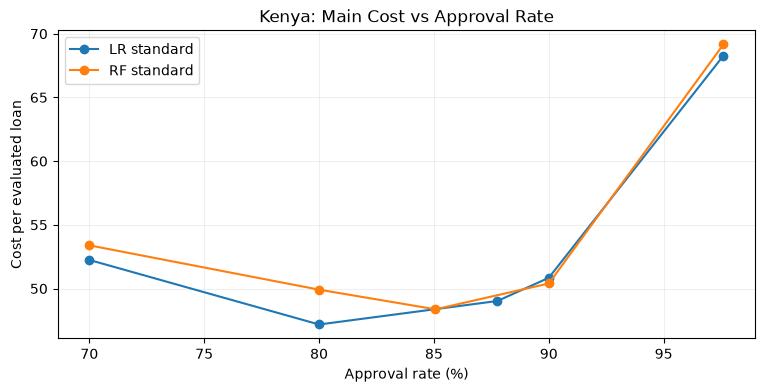

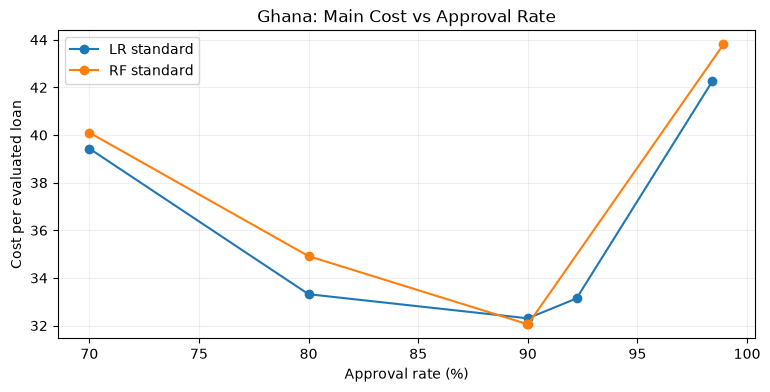

In [8]:
for country in ["Kenya", "Ghana"]:

    subset = sensitivity[
        sensitivity["country"] == country
    ]

    fig, ax = plt.subplots(figsize=(9, 4))

    for model, group in subset.groupby("model"):

        group = group.sort_values("approval_rate")

        ax.plot(
            group["approval_rate"] * 100,
            group["main_cost_per_loan"],
            marker="o",
            label=model,
        )

    ax.set_title(
        f"{country}: Main Cost vs Approval Rate"
    )

    ax.set_xlabel("Approval rate (%)")
    ax.set_ylabel("Cost per evaluated loan")
    ax.grid(alpha=0.2)
    ax.legend()

    plt.show()


## 8. Model Decision

**Current conclusion: Provisional**

Logistic Regression achieved stronger reported
PR-AUC under customer-cluster bootstrap analysis.

Random Forest achieved lower observed costs
under the main country thresholds.

Logistic Regression performed better under
several approval-constrained comparisons.

No single model dominates every metric.

Therefore, both calibrated candidates are
retained pending final temporal, calibration,
cost and fairness verification.


## 9. Limitations and Outstanding Checks

1. Reconcile 54,463 evaluated observations
   against 68,464 processed training records.
2. Verify chronological fold construction.
3. Check calibration stability across time.
4. Prevent model-selection optimism.
5. Validate country-specific costs.
6. Review fairness and regulatory constraints.
7. Verify all assignment requirements.

**Deployment authorization: Not granted.**
